**Segmentasi Citra Berbasis Similaritas: Clustering dan Watershed**

---

### 1. Konsep Segmentasi Berbasis Clustering

Segmentasi berbasis clustering memanfaatkan algoritma pembelajaran tak terawasi (unsupervised learning) untuk mengelompokkan piksel berdasarkan fitur seperti intensitas, warna, atau koordinat spasial.

Algoritma yang umum digunakan:

* **K-Means Clustering**: Mengelompokkan piksel ke dalam *k* klaster berdasarkan jarak ke pusat klaster.
* **Mean Shift**, **DBSCAN**, dan lain-lain.

### 2. Implementasi K-Means Clustering

```python
  import cv2
  import numpy as np
  import matplotlib.pyplot as plt

  img = cv2.imread('image.jpg')
  img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  plt.imshow(img_rgb)
  plt.title('RGB Original Image')
  plt.axis('off')
  plt.show()

  Z = img_rgb.reshape((-1,3))
  Z = np.float32(Z)

  criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
  K = 3
  ret,label,center=cv2.kmeans(Z,K,None,criteria,10,cv2.KMEANS_RANDOM_CENTERS)

  center = np.uint8(center)
  res = center[label.flatten()]
  segmented_img = res.reshape((img.shape))

  plt.imshow(segmented_img)
  plt.title('K-Means Segmentation')
  plt.axis('off')
  plt.show()
```

### 3. Konsep Segmentasi Watershed

Watershed adalah algoritma berbasis morfologi yang memodelkan citra sebagai topografi. Area terang (intensitas tinggi) dianggap sebagai puncak dan area gelap (intensitas rendah) sebagai lembah. Tujuannya adalah membanjiri lembah dari marker (penanda), lalu membuat batas di titik pertemuan antara banjir.
Watershed efektif jika dikombinasikan dengan marker dan preprocessing.

### 4. Implementasi Watershed di Python

```python
  img = cv2.imread('image.jpg')
  gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

  # Noise removal
  kernel = np.ones((3,3), np.uint8)
  opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

  # Sure background
  sure_bg = cv2.dilate(opening, kernel, iterations=3)

  # Sure foreground
  dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
  ret, sure_fg = cv2.threshold(dist_transform, 0.7*dist_transform.max(), 255, 0)

  # Unknown region
  sure_fg = np.uint8(sure_fg)
  unknown = cv2.subtract(sure_bg, sure_fg)

  # Marker labelling
  ret, markers = cv2.connectedComponents(sure_fg)
  markers = markers + 1
  markers[unknown == 255] = 0

  markers = cv2.watershed(img, markers)
  img[markers == -1] = [255, 0, 0]

  plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  plt.title('Watershed Result')
  plt.axis('off')
  plt.show()
```

---

### 5. Visualisasi Eksperimen Tambahan

#### Menguji jumlah klaster *K* yang berbeda pada K-Means:
```python
  for k in [2, 4, 6]:
      _, labels, centers = cv2.kmeans(np.float32(img_reshaped), k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
      segmented_img = centers[labels.flatten()].reshape(img.shape).astype(np.uint8)
      plt.figure()
      plt.imshow(cv2.cvtColor(segmented_img, cv2.COLOR_BGR2RGB))
      plt.title(f'K-Means with k={k}')
      plt.axis('off')
      plt.show()
```

#### Menambahkan Preprocessing dengan CLAHE untuk Watershed:
```python
  clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
  gray_clahe = clahe.apply(gray)
  # Gunakan gray_clahe dalam preprocessing untuk Watershed
```

#### Menggabungkan Watershed dengan Deteksi Tepi dan Thresholding untuk Marker Lebih Akurat:
```python
  edges = cv2.Canny(gray, 100, 200)
  edges_dilated = cv2.dilate(edges, kernel, iterations=1)
  ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
  combined_marker = cv2.bitwise_or(edges_dilated, thresh)
  # Lanjutkan dengan langkah marker dan watershed seperti sebelumnya
  # Gunakan 'combined_marker' sebagai referensi untuk sure_fg
```

#### Mengkombinasikan Clustering dan Watershed untuk Segmentasi Lebih Akurat:
Gabungan clustering (misalnya K-Means) dan watershed dapat meningkatkan akurasi segmentasi.
* Gunakan hasil clustering sebagai dasar penentuan marker.
* Terapkan watershed berdasarkan hasil threshold dari cluster tertentu atau perbedaan antar cluster.

```python
  # Asumsikan segmented_img dari K-Means telah tersedia
  gray_clustered = cv2.cvtColor(segmented_img, cv2.COLOR_RGB2GRAY)
  ret, thresh_clustered = cv2.threshold(gray_clustered, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

  # Preprocessing untuk marker
  opening = cv2.morphologyEx(thresh_clustered, cv2.MORPH_OPEN, kernel, iterations=2)
  sure_bg = cv2.dilate(opening, kernel, iterations=3)
  dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
  ret, sure_fg = cv2.threshold(dist_transform, 0.7 * dist_transform.max(), 255, 0)
  sure_fg = np.uint8(sure_fg)
  unknown = cv2.subtract(sure_bg, sure_fg)

  ret, markers = cv2.connectedComponents(sure_fg)
  markers = markers + 1
  markers[unknown == 255] = 0

  markers = cv2.watershed(img, markers)
  img[markers == -1] = [255, 0, 0]

  plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  plt.title('Clustering + Watershed')
  plt.axis('off')
  plt.show()
```

---

### 6. Kesimpulan

* Segmentasi berbasis clustering efektif untuk pemisahan objek berdasarkan kesamaan warna/intensitas (tekstur homogen), sementara watershed sangat baik untuk segmentasi objek bersentuhan (objek dengan batas yang jelas).
* Eksperimen parameter penting untuk mendapatkan hasil segmentasi terbaik.
* Preprocessing seperti CLAHE, serta deteksi tepi dan thresholding sangat membantu dalam memperjelas batas objek.
* Kombinasikan Clustering dan Watershed dapat menghasilkan segmentasi yang lebih akurat.

In [1]:
# Citra: chef.jpg (kucing putih memasak sup oranye di dapur)
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

def show_grid(images, titles, cols=4, size=3.2, cmap='gray', suptitle=None):
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=(size * cols, size * rows))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(im, cmap=None if im.ndim == 3 else cmap)
        plt.title(t, fontsize=9)
        plt.axis('off')
    if suptitle:
        plt.suptitle(suptitle, fontsize=12)
    plt.tight_layout()
    plt.show()

Ukuran citra: (673, 736, 3)

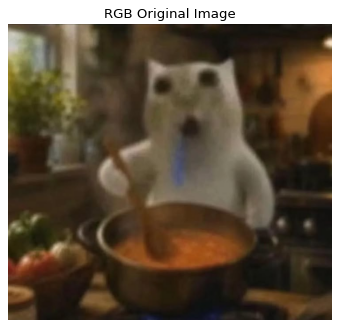

In [2]:
# 1. K-Means Clustering (template, K=3)
img = cv2.imread('chef.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print('Ukuran citra:', img.shape)
plt.imshow(img_rgb)
plt.title('RGB Original Image')
plt.axis('off')
plt.show()

Compactness (SSE): 379987735.9792174
Pusat klaster (RGB):
 [[137 122  97]
 [ 99  75  46]
 [ 45  34  20]]

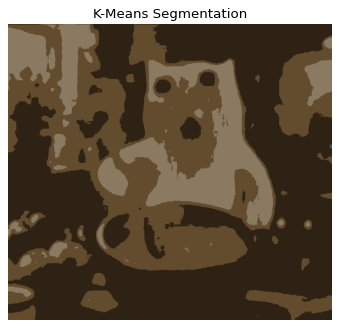

In [3]:
Z = img_rgb.reshape((-1, 3))
Z = np.float32(Z)

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
K = 3
ret, label, center = cv2.kmeans(Z, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

center = np.uint8(center)
res = center[label.flatten()]
segmented_img = res.reshape((img.shape))

print('Compactness (SSE):', ret)
print('Pusat klaster (RGB):\n', center)
plt.imshow(segmented_img)
plt.title('K-Means Segmentation')
plt.axis('off')
plt.show()

  K |    compactness | waktu (s)
  2 |      637959684 |      0.16
  3 |      379830657 |      0.21
  4 |      276797771 |      0.26
  5 |      222299107 |      0.26
  6 |      173021033 |      0.30
  8 |      127910123 |      0.30
 12 |       84945651 |      0.48

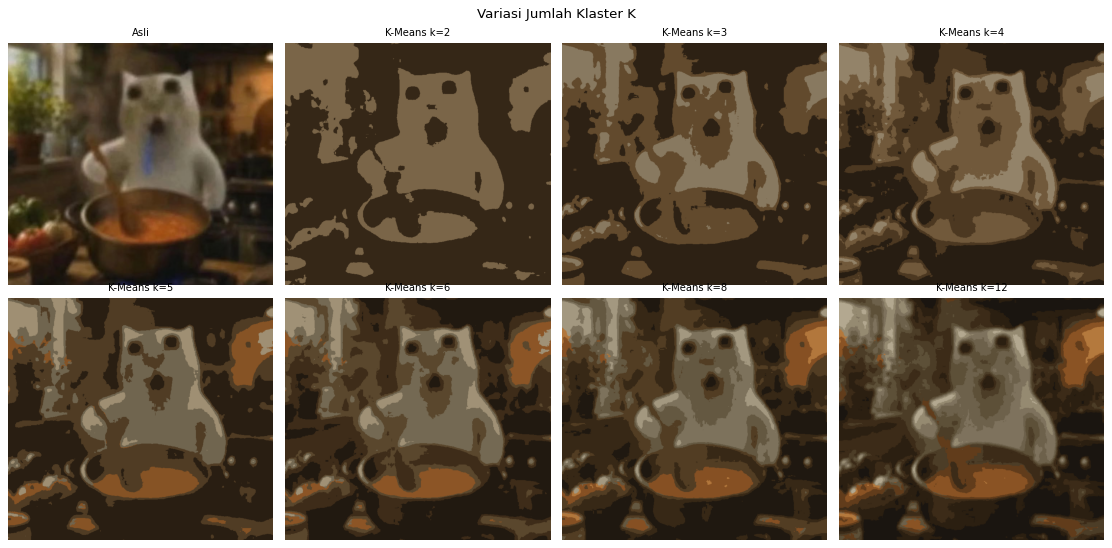

In [4]:
# 2. Eksperimen jumlah klaster K
def kmeans_seg(features, K, shape, attempts=10, flags=cv2.KMEANS_PP_CENTERS, crit=criteria, seed=0):
    cv2.setRNGSeed(seed)
    ret, lab, cen = cv2.kmeans(np.float32(features), K, None, crit, attempts, flags)
    return ret, lab.reshape(shape[:2]), cen

ims, tts = [img_rgb], ['Asli']
print(f"{'K':>3} | {'compactness':>14} | {'waktu (s)':>9}")
for k in [2, 3, 4, 5, 6, 8, 12]:
    t0 = time.time()
    ret_k, lab_k, cen_k = kmeans_seg(Z, k, img.shape)
    dt = time.time() - t0
    print(f"{k:>3} | {ret_k:>14.0f} | {dt:>9.2f}")
    ims.append(np.uint8(cen_k)[lab_k])
    tts.append(f'K-Means k={k}')
show_grid(ims, tts, cols=4, size=3.5, suptitle='Variasi Jumlah Klaster K')

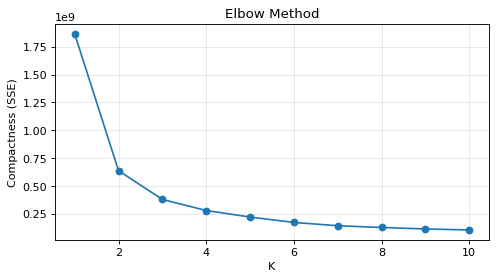

K=1 -> 2: SSE turun 65.8%
K=2 -> 3: SSE turun 40.4%
K=3 -> 4: SSE turun 26.1%
K=4 -> 5: SSE turun 20.8%
K=5 -> 6: SSE turun 21.8%
K=6 -> 7: SSE turun 17.0%
K=7 -> 8: SSE turun 10.8%
K=8 -> 9: SSE turun 10.4%
K=9 -> 10: SSE turun 7.9%

In [5]:
# 2.1 Elbow method untuk memilih K
ks = list(range(1, 11))
sse = [kmeans_seg(Z, k, img.shape, attempts=3)[0] for k in ks]
plt.figure(figsize=(7, 3.5))
plt.plot(ks, sse, 'o-')
plt.xlabel('K'), plt.ylabel('Compactness (SSE)')
plt.title('Elbow Method')
plt.grid(alpha=.3)
plt.show()

drop = -np.diff(sse) / np.array(sse[:-1]) * 100
for k, d in zip(ks[1:], drop):
    print(f'K={k-1} -> {k}: SSE turun {d:.1f}%')

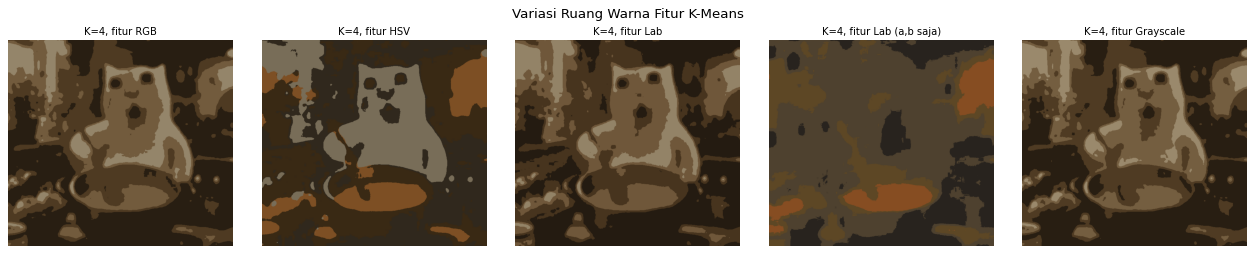

In [6]:
# 3. Eksperimen ruang warna (K=4)
blur = cv2.GaussianBlur(img, (5, 5), 0)
spaces = {
    'RGB': cv2.cvtColor(blur, cv2.COLOR_BGR2RGB),
    'HSV': cv2.cvtColor(blur, cv2.COLOR_BGR2HSV),
    'Lab': cv2.cvtColor(blur, cv2.COLOR_BGR2LAB),
    'Lab (a,b saja)': cv2.cvtColor(blur, cv2.COLOR_BGR2LAB)[:, :, 1:],
    'Grayscale': cv2.cvtColor(blur, cv2.COLOR_BGR2GRAY)[..., None],
}
ims, tts = [], []
for name, sp in spaces.items():
    _, lab_k, _ = kmeans_seg(sp.reshape(-1, sp.shape[2]), 4, img.shape)
    # warnai setiap klaster dengan rata-rata warna RGB aslinya agar mudah dibandingkan
    vis = np.zeros_like(img_rgb)
    for c in range(4):
        vis[lab_k == c] = img_rgb[lab_k == c].mean(axis=0)
    ims.append(vis)
    tts.append(f'K=4, fitur {name}')
show_grid(ims, tts, cols=5, size=3.2, suptitle='Variasi Ruang Warna Fitur K-Means')

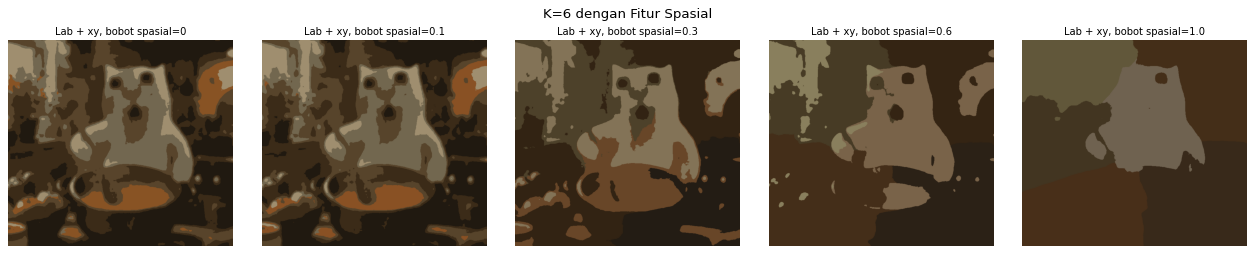

In [7]:
# 4. Eksperimen fitur spasial (warna + koordinat x, y)
lab_img = spaces['Lab'].astype(np.float32)
h, w = img.shape[:2]
yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
ims, tts = [], []
for wgt in [0, 0.1, 0.3, 0.6, 1.0]:
    # koordinat dinormalisasi ke rentang 0..255 lalu diberi bobot
    feat = np.dstack([lab_img, wgt * xx / w * 255, wgt * yy / h * 255]).reshape(-1, 5)
    _, lab_k, _ = kmeans_seg(feat, 6, img.shape, attempts=3)
    vis = np.zeros_like(img_rgb)
    for c in range(6):
        vis[lab_k == c] = img_rgb[lab_k == c].mean(axis=0)
    ims.append(vis)
    tts.append(f'Lab + xy, bobot spasial={wgt}')
show_grid(ims, tts, cols=5, size=3.2, suptitle='K=6 dengan Fitur Spasial')

In [8]:
# 5. Eksperimen inisialisasi, attempts, dan kriteria berhenti
print(f"{'flags':>16} | {'attempts':>8} | {'compactness':>14} | {'waktu (s)':>9}")
for flags, fname in [(cv2.KMEANS_RANDOM_CENTERS, 'RANDOM_CENTERS'), (cv2.KMEANS_PP_CENTERS, 'PP_CENTERS')]:
    for att in [1, 3, 10]:
        res_list = []
        t0 = time.time()
        for sd in range(3):
            res_list.append(kmeans_seg(Z, 4, img.shape, attempts=att, flags=flags, seed=sd)[0])
        dt = (time.time() - t0) / 3
        print(f"{fname:>16} | {att:>8} | {np.mean(res_list):>14.0f} | {dt:>9.2f}   (std antar seed: {np.std(res_list):.0f})")

           flags | attempts |    compactness | waktu (s)
  RANDOM_CENTERS |        1 |      295078608 |      0.04   (std antar seed: 20903696)
  RANDOM_CENTERS |        3 |      286418629 |      0.10   (std antar seed: 9001048)
  RANDOM_CENTERS |       10 |      278062000 |      0.31   (std antar seed: 1349106)
      PP_CENTERS |        1 |      282753604 |      0.04   (std antar seed: 4823925)
      PP_CENTERS |        3 |      278286231 |      0.08   (std antar seed: 1829859)
      PP_CENTERS |       10 |      276654956 |      0.27   (std antar seed: 110596)

max_iter |    eps |    compactness | waktu (s)
       1 |    1.0 |     1493530358 |      0.01
       3 |    1.0 |      662091404 |      0.01
      10 |    1.0 |      324289771 |      0.03
     100 |    0.1 |      276487794 |      0.07

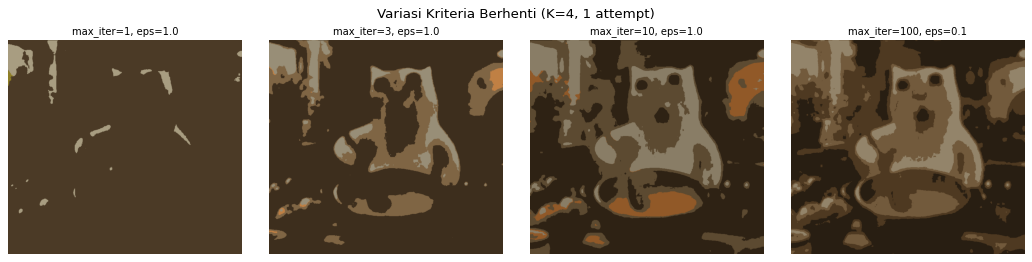

In [9]:
print(f"{'max_iter':>8} | {'eps':>6} | {'compactness':>14} | {'waktu (s)':>9}")
ims, tts = [], []
for max_iter, eps in [(1, 1.0), (3, 1.0), (10, 1.0), (100, 0.1)]:
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, max_iter, eps)
    t0 = time.time()
    ret_k, lab_k, cen_k = kmeans_seg(Z, 4, img.shape, attempts=1, flags=cv2.KMEANS_RANDOM_CENTERS, crit=crit)
    print(f"{max_iter:>8} | {eps:>6} | {ret_k:>14.0f} | {time.time()-t0:>9.2f}")
    ims.append(np.uint8(cen_k)[lab_k])
    tts.append(f'max_iter={max_iter}, eps={eps}')
show_grid(ims, tts, cols=4, size=3.3, suptitle='Variasi Kriteria Berhenti (K=4, 1 attempt)')

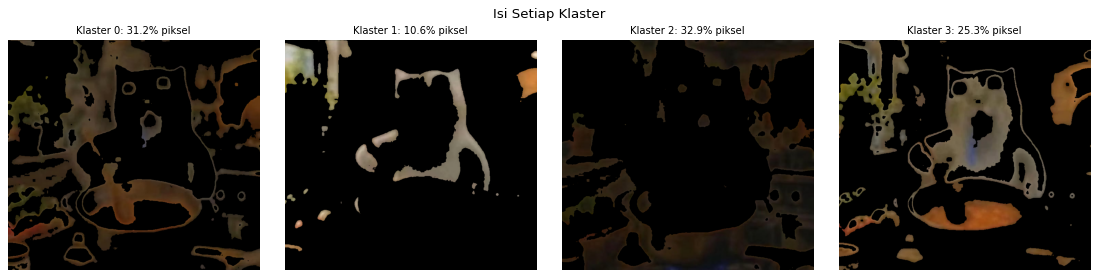

In [10]:
# 6. Visualisasi tiap klaster (K=4, Lab)
_, lab4, _ = kmeans_seg(spaces['Lab'].reshape(-1, 3), 4, img.shape)
ims, tts = [], []
for c in range(4):
    m = (lab4 == c).astype(np.uint8) * 255
    ims.append(cv2.bitwise_and(img_rgb, img_rgb, mask=m))
    tts.append(f'Klaster {c}: {100 * (lab4 == c).mean():.1f}% piksel')
show_grid(ims, tts, cols=4, size=3.5, suptitle='Isi Setiap Klaster')

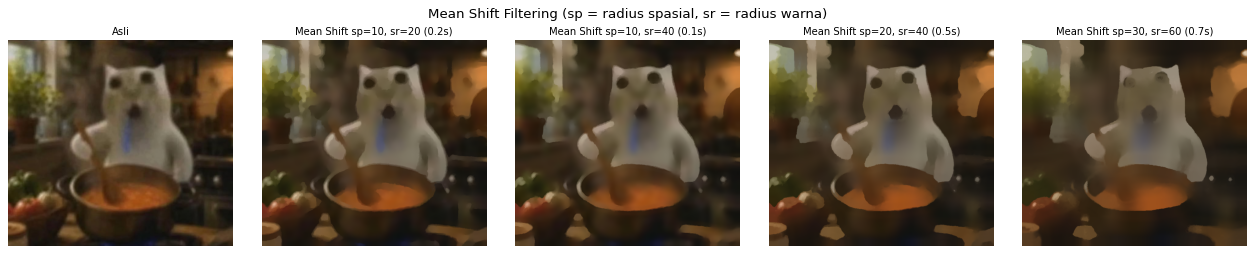

In [11]:
# 7. Metode clustering lain: Mean Shift dan SLIC
ims, tts = [img_rgb], ['Asli']
for sp, sr in [(10, 20), (10, 40), (20, 40), (30, 60)]:
    t0 = time.time()
    ms = cv2.pyrMeanShiftFiltering(img, sp, sr)
    ims.append(cv2.cvtColor(ms, cv2.COLOR_BGR2RGB))
    tts.append(f'Mean Shift sp={sp}, sr={sr} ({time.time()-t0:.1f}s)')
show_grid(ims, tts, cols=5, size=3.2, suptitle='Mean Shift Filtering (sp = radius spasial, sr = radius warna)')

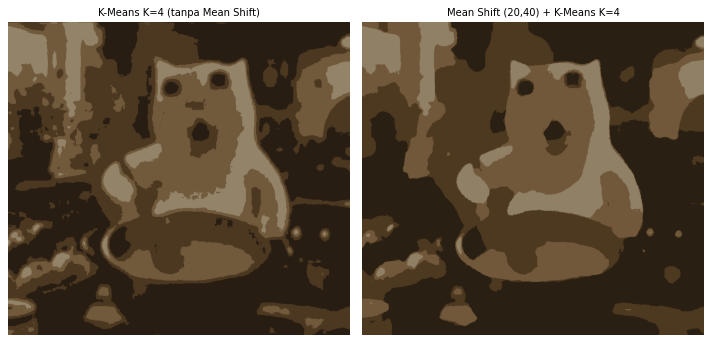

In [12]:
ms = cv2.pyrMeanShiftFiltering(img, 20, 40)
_, lab_ms, cen_ms = kmeans_seg(cv2.cvtColor(ms, cv2.COLOR_BGR2RGB).reshape(-1, 3), 4, img.shape)
_, lab_raw, cen_raw = kmeans_seg(Z, 4, img.shape)
show_grid([np.uint8(cen_raw)[lab_raw], np.uint8(cen_ms)[lab_ms]],
          ['K-Means K=4 (tanpa Mean Shift)', 'Mean Shift (20,40) + K-Means K=4'], cols=2, size=4.5)

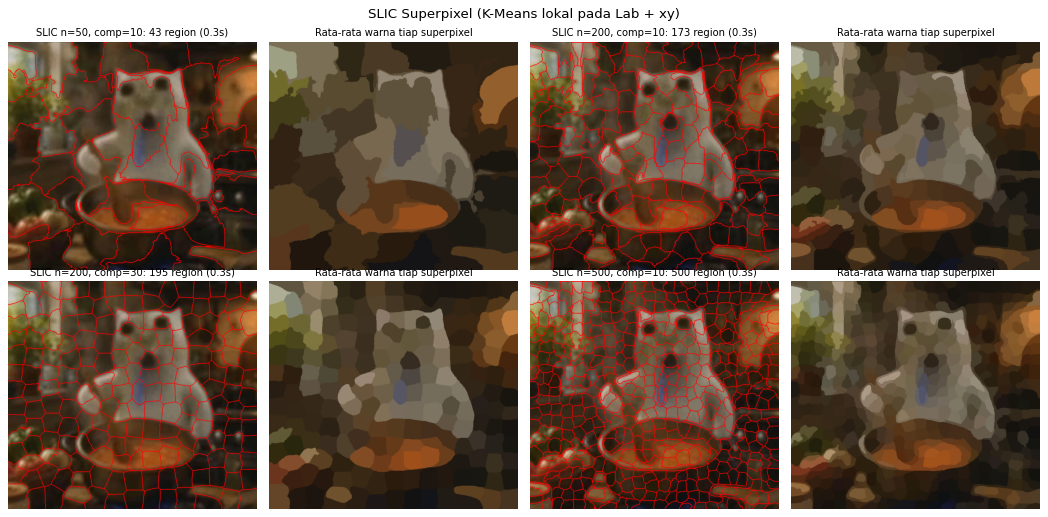

In [13]:
from skimage.segmentation import slic, mark_boundaries
from skimage.color import label2rgb

ims, tts = [], []
for n_seg, comp in [(50, 10), (200, 10), (200, 30), (500, 10)]:
    t0 = time.time()
    sp_lab = slic(img_rgb, n_segments=n_seg, compactness=comp, start_label=1)
    dt = time.time() - t0
    ims.append(mark_boundaries(img_rgb, sp_lab, color=(1, 0, 0)))
    tts.append(f'SLIC n={n_seg}, comp={comp}: {sp_lab.max()} region ({dt:.1f}s)')
    ims.append(label2rgb(sp_lab, img_rgb, kind='avg'))
    tts.append('Rata-rata warna tiap superpixel')
show_grid(ims, tts, cols=4, size=3.3, suptitle='SLIC Superpixel (K-Means lokal pada Lab + xy)')

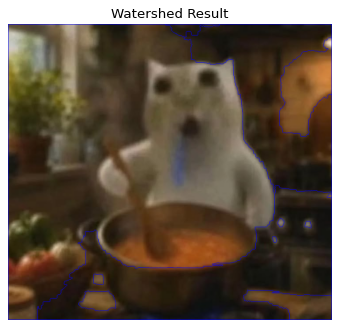

In [14]:
# 8. Watershed (template)
img_ws = img.copy()
gray = cv2.cvtColor(img_ws, cv2.COLOR_BGR2GRAY)
ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Noise removal
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

# Sure background
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# Sure foreground
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
ret, sure_fg = cv2.threshold(dist_transform, 0.7 * dist_transform.max(), 255, 0)

# Unknown region
sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)

# Marker labelling
ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

markers = cv2.watershed(img_ws, markers)
img_ws[markers == -1] = [255, 0, 0]

plt.imshow(cv2.cvtColor(img_ws, cv2.COLOR_BGR2RGB))
plt.title('Watershed Result')
plt.axis('off')
plt.show()

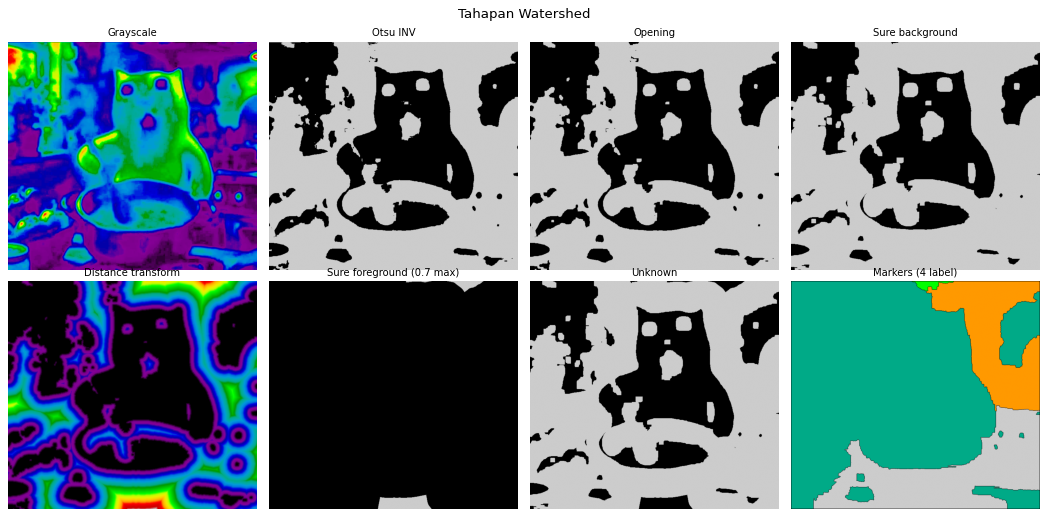

In [15]:
# Visualisasi tiap tahap watershed
show_grid([gray, thresh, opening, sure_bg, dist_transform, sure_fg, unknown, markers],
          ['Grayscale', 'Otsu INV', 'Opening', 'Sure background', 'Distance transform',
           'Sure foreground (0.7 max)', 'Unknown', f'Markers ({markers.max()} label)'],
          cols=4, size=3.3, cmap='nipy_spectral', suptitle='Tahapan Watershed')

Threshold Otsu: 72.0

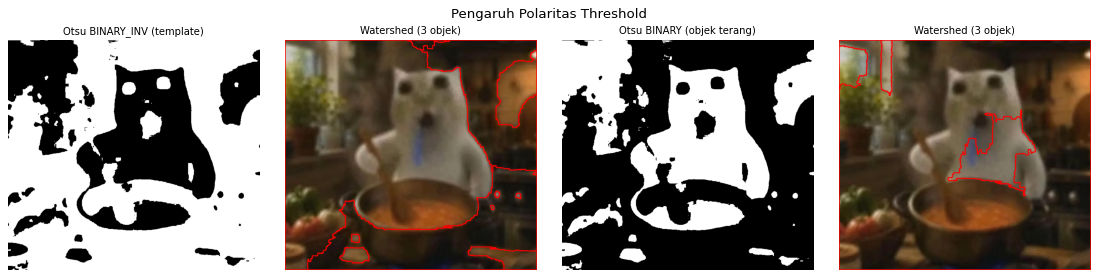

In [16]:
# 9. Eksperimen watershed
def watershed_pipeline(bgr, binary, open_iter=2, dil_iter=3, dist_ratio=0.7, dist_type=cv2.DIST_L2, mask_size=5, ksize=3):
    kernel = np.ones((ksize, ksize), np.uint8)
    opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=open_iter)
    sure_bg = cv2.dilate(opening, kernel, iterations=dil_iter)
    dist = cv2.distanceTransform(opening, dist_type, mask_size)
    _, sure_fg = cv2.threshold(dist, dist_ratio * dist.max(), 255, 0)
    sure_fg = np.uint8(sure_fg)
    unknown = cv2.subtract(sure_bg, sure_fg)
    n, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0
    markers = cv2.watershed(bgr.copy(), markers)
    out = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    out[cv2.dilate((markers == -1).astype(np.uint8), np.ones((3, 3), np.uint8)) > 0] = [255, 0, 0]
    return out, markers, n - 1

_, th_inv = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
T_otsu, th_bin = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
r1, m1, n1 = watershed_pipeline(img, th_inv)
r2, m2, n2 = watershed_pipeline(img, th_bin)
print('Threshold Otsu:', T_otsu)
show_grid([th_inv, r1, th_bin, r2],
          ['Otsu BINARY_INV (template)', f'Watershed ({n1} objek)', 'Otsu BINARY (objek terang)', f'Watershed ({n2} objek)'],
          cols=4, size=3.5, suptitle='Pengaruh Polaritas Threshold')

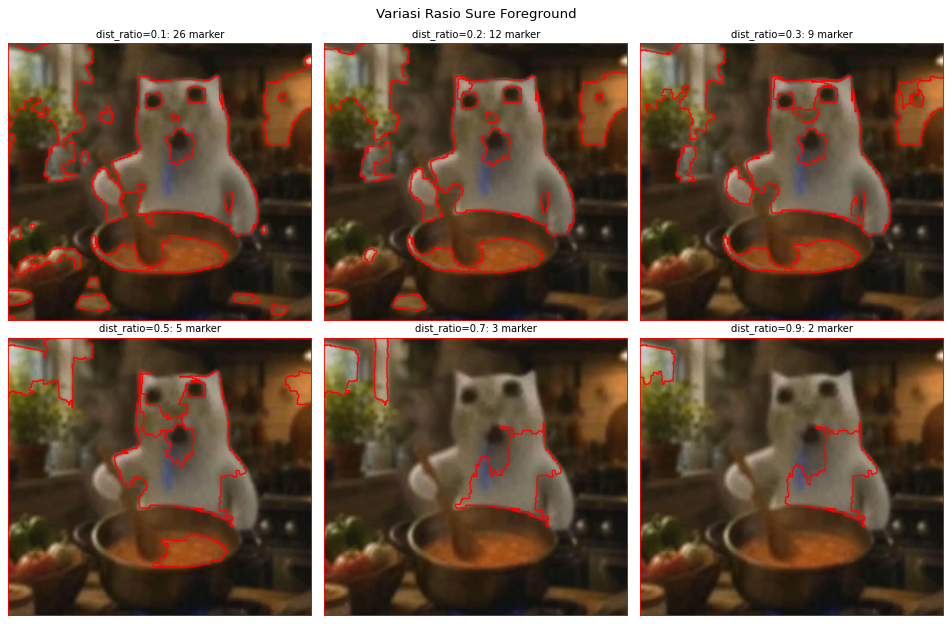

In [17]:
# Variasi rasio threshold distance transform untuk sure foreground
ims, tts = [], []
for ratio in [0.1, 0.2, 0.3, 0.5, 0.7, 0.9]:
    r, m, n = watershed_pipeline(img, th_bin, dist_ratio=ratio)
    ims.append(r)
    tts.append(f'dist_ratio={ratio}: {n} marker')
show_grid(ims, tts, cols=3, size=4, suptitle='Variasi Rasio Sure Foreground')

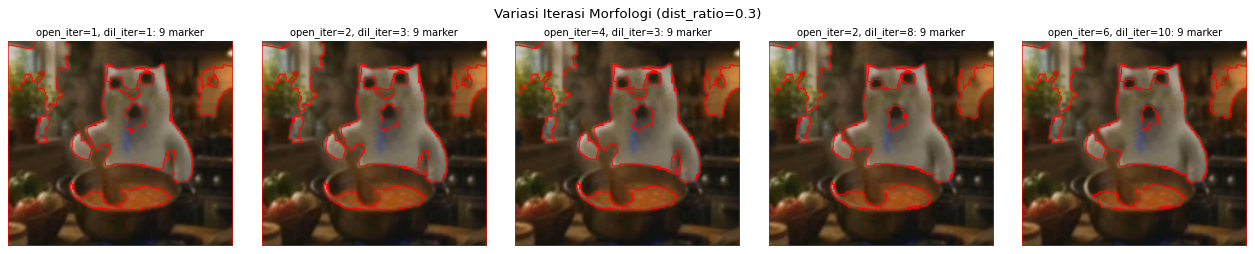

In [18]:
# Variasi iterasi opening dan dilasi (sure background)
ims, tts = [], []
for oi, di in [(1, 1), (2, 3), (4, 3), (2, 8), (6, 10)]:
    r, m, n = watershed_pipeline(img, th_bin, open_iter=oi, dil_iter=di, dist_ratio=0.3)
    ims.append(r)
    tts.append(f'open_iter={oi}, dil_iter={di}: {n} marker')
show_grid(ims, tts, cols=5, size=3.2, suptitle='Variasi Iterasi Morfologi (dist_ratio=0.3)')

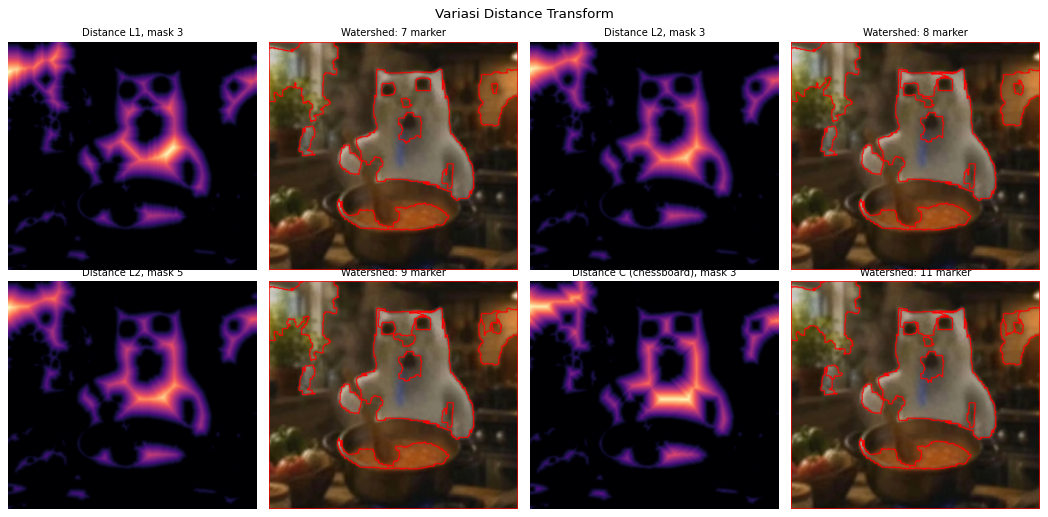

In [19]:
# Variasi tipe distance transform
ims, tts = [], []
for dt_type, dname, msz in [(cv2.DIST_L1, 'L1', 3), (cv2.DIST_L2, 'L2', 3), (cv2.DIST_L2, 'L2', 5), (cv2.DIST_C, 'C (chessboard)', 3)]:
    opening_b = cv2.morphologyEx(th_bin, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8), iterations=2)
    d = cv2.distanceTransform(opening_b, dt_type, msz)
    r, m, n = watershed_pipeline(img, th_bin, dist_ratio=0.3, dist_type=dt_type, mask_size=msz)
    ims += [d, r]
    tts += [f'Distance {dname}, mask {msz}', f'Watershed: {n} marker']
show_grid(ims, tts, cols=4, size=3.3, cmap='magma', suptitle='Variasi Distance Transform')

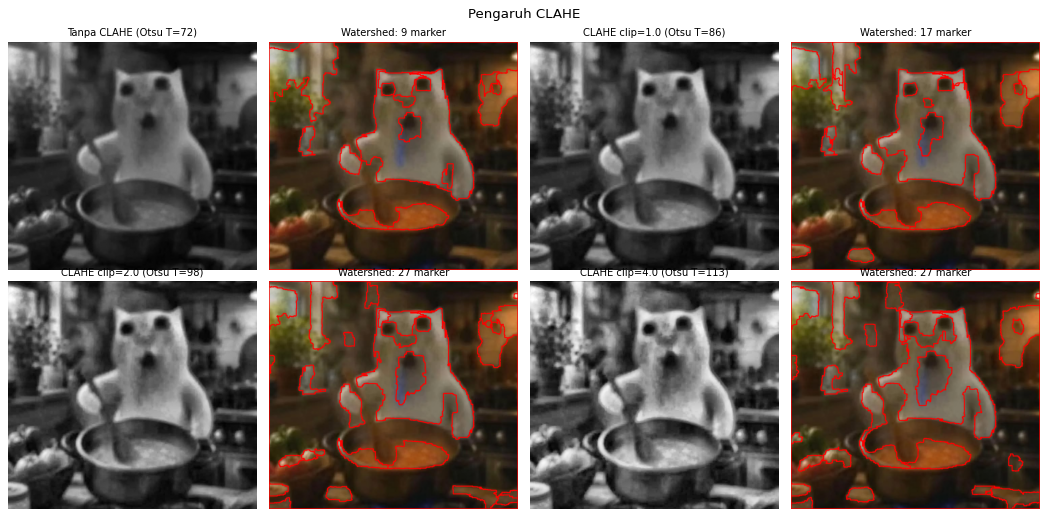

In [20]:
# 10. Preprocessing CLAHE untuk watershed
ims, tts = [], []
for clip in [None, 1.0, 2.0, 4.0]:
    if clip is None:
        g = gray
        name = 'Tanpa CLAHE'
    else:
        g = cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(gray)
        name = f'CLAHE clip={clip}'
    t, th = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    r, m, n = watershed_pipeline(img, th, dist_ratio=0.3)
    ims += [g, r]
    tts += [f'{name} (Otsu T={t:.0f})', f'Watershed: {n} marker']
show_grid(ims, tts, cols=4, size=3.3, suptitle='Pengaruh CLAHE')

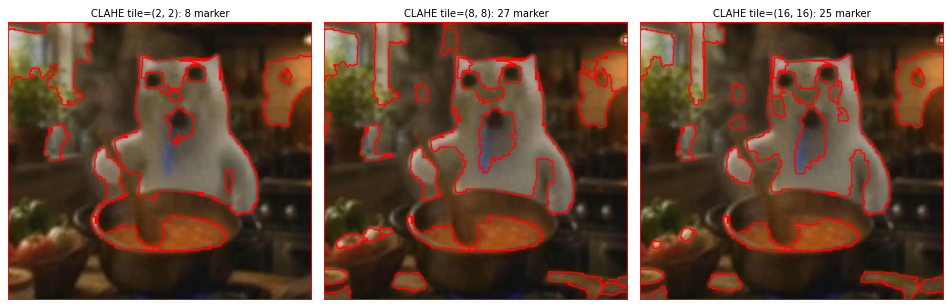

In [21]:
# Variasi tileGridSize CLAHE
ims, tts = [], []
for tile in [(2, 2), (8, 8), (16, 16)]:
    g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=tile).apply(gray)
    _, th = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    r, m, n = watershed_pipeline(img, th, dist_ratio=0.3)
    ims.append(r)
    tts.append(f'CLAHE tile={tile}: {n} marker')
show_grid(ims, tts, cols=3, size=4)

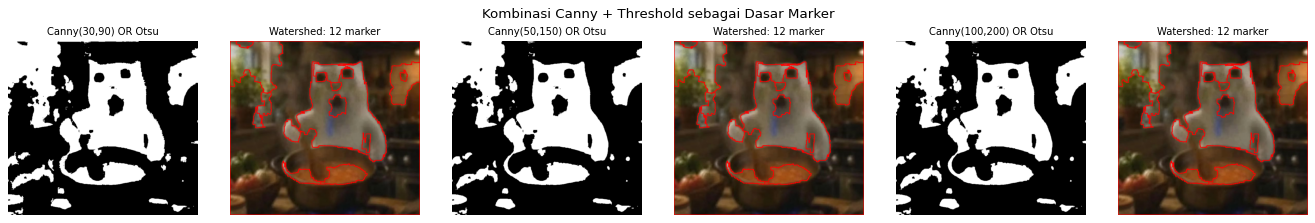

In [22]:
# 11. Watershed + deteksi tepi + thresholding
kernel = np.ones((3, 3), np.uint8)
ims, tts = [], []
for lo, hi in [(30, 90), (50, 150), (100, 200)]:
    edges = cv2.Canny(gray, lo, hi)
    edges_dilated = cv2.dilate(edges, kernel, iterations=1)
    combined_marker = cv2.bitwise_or(edges_dilated, th_bin)
    # isi area yang tertutup tepi agar objek lebih padat
    combined_closed = cv2.morphologyEx(combined_marker, cv2.MORPH_CLOSE, kernel, iterations=3)
    r, m, n = watershed_pipeline(img, combined_closed, dist_ratio=0.3)
    ims += [combined_marker, r]
    tts += [f'Canny({lo},{hi}) OR Otsu', f'Watershed: {n} marker']
show_grid(ims, tts, cols=6, size=2.8, suptitle='Kombinasi Canny + Threshold sebagai Dasar Marker')

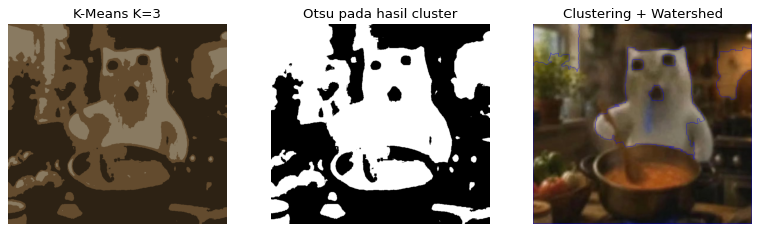

In [23]:
# 12. Clustering + Watershed
# K-Means K=3 (template)
gray_clustered = cv2.cvtColor(segmented_img, cv2.COLOR_RGB2GRAY)
ret, thresh_clustered = cv2.threshold(gray_clustered, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

opening = cv2.morphologyEx(thresh_clustered, cv2.MORPH_OPEN, kernel, iterations=2)
sure_bg = cv2.dilate(opening, kernel, iterations=3)
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
ret, sure_fg = cv2.threshold(dist_transform, 0.7 * dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)

ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

img_cw = img.copy()
markers = cv2.watershed(img_cw, markers)
img_cw[markers == -1] = [255, 0, 0]

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1), plt.imshow(segmented_img), plt.title('K-Means K=3'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(thresh_clustered, cmap='gray'), plt.title('Otsu pada hasil cluster'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(cv2.cvtColor(img_cw, cv2.COLOR_BGR2RGB)), plt.title('Clustering + Watershed'), plt.axis('off')
plt.show()

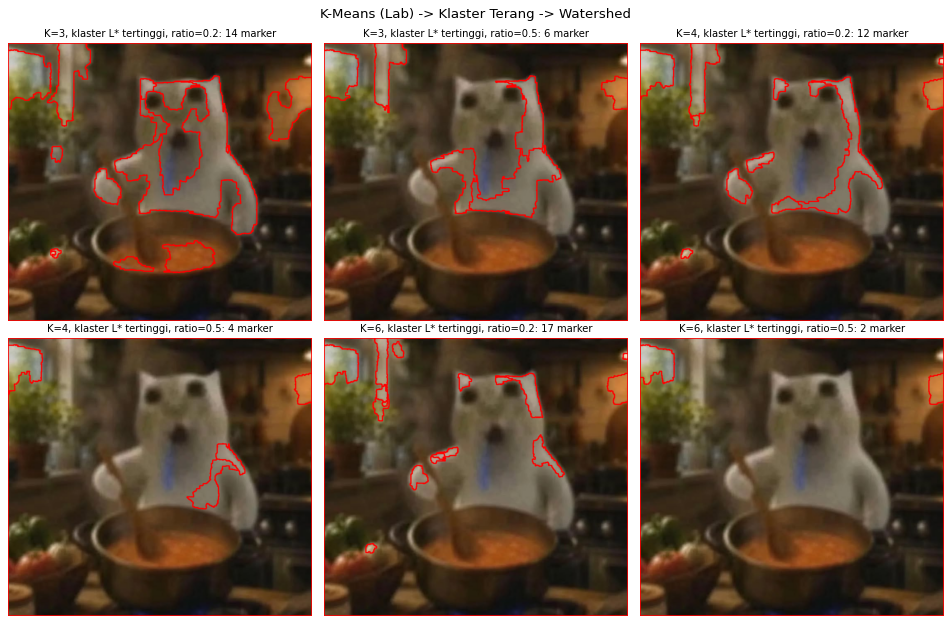

In [24]:
# Eksperimen: pilih klaster tertentu sebagai foreground (bukan Otsu), variasi K dan dist_ratio
lab_feat = spaces['Lab'].reshape(-1, 3)
ims, tts = [], []
for k in [3, 4, 6]:
    _, lab_k, cen_k = kmeans_seg(lab_feat, k, img.shape)
    # klaster dengan L* tertinggi = bulu kucing putih
    bright = np.argmax(cen_k[:, 0])
    fg = (lab_k == bright).astype(np.uint8) * 255
    for ratio in [0.2, 0.5]:
        r, m, n = watershed_pipeline(img, fg, dist_ratio=ratio)
        ims.append(r)
        tts.append(f'K={k}, klaster L* tertinggi, ratio={ratio}: {n} marker')
show_grid(ims, tts, cols=3, size=4, suptitle='K-Means (Lab) -> Klaster Terang -> Watershed')

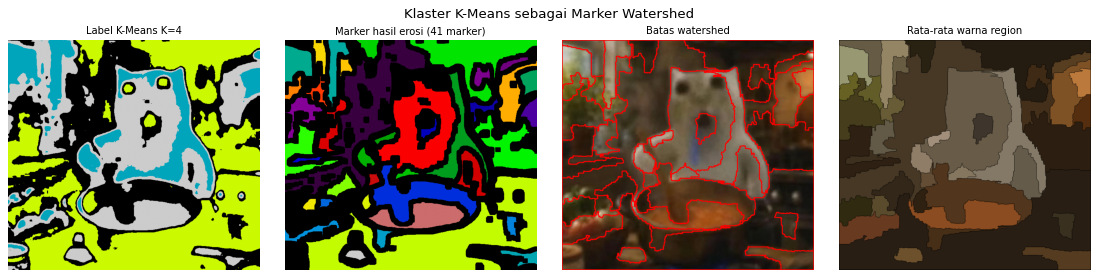

In [25]:
# Eksperimen: setiap klaster K-Means menjadi marker, watershed memperhalus batas antar klaster
_, lab_k, _ = kmeans_seg(spaces['Lab'].reshape(-1, 3), 4, img.shape)
markers_k = np.zeros(img.shape[:2], np.int32)
er = np.ones((7, 7), np.uint8)
for c in range(4):
    core = cv2.erode((lab_k == c).astype(np.uint8), er, iterations=2)
    n_c, comp = cv2.connectedComponents(core)
    # komponen kecil diabaikan agar marker tidak terlalu banyak
    for j in range(1, n_c):
        if (comp == j).sum() > 500:
            markers_k[comp == j] = markers_k.max() + 1
ws = cv2.watershed(img.copy(), markers_k.copy())
vis = img_rgb.copy()
vis[cv2.dilate((ws == -1).astype(np.uint8), np.ones((3, 3), np.uint8)) > 0] = [255, 0, 0]
avg = np.zeros_like(img_rgb)
for l in np.unique(ws):
    if l > 0:
        avg[ws == l] = img_rgb[ws == l].mean(axis=0)
show_grid([np.uint8(lab_k), markers_k, vis, avg],
          ['Label K-Means K=4', f'Marker hasil erosi ({markers_k.max()} marker)', 'Batas watershed', 'Rata-rata warna region'],
          cols=4, size=3.5, cmap='nipy_spectral', suptitle='Klaster K-Means sebagai Marker Watershed')

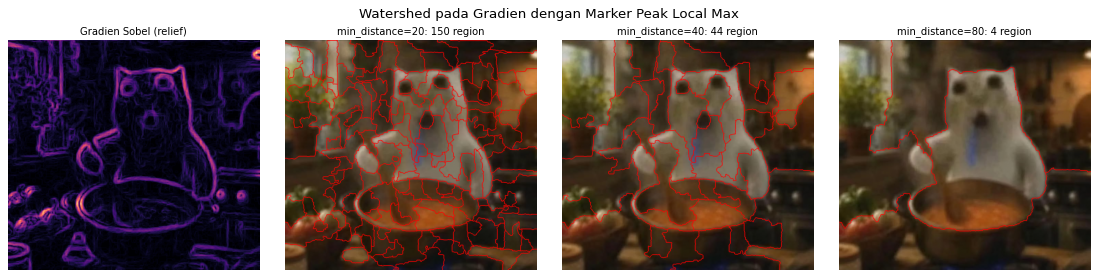

In [26]:
# 13. Watershed berbasis gradien (scikit-image) dengan marker otomatis
from skimage.segmentation import watershed as sk_watershed
from skimage.filters import sobel
from skimage.feature import peak_local_max
from scipy import ndimage as ndi

gradient = sobel(cv2.GaussianBlur(gray, (5, 5), 0) / 255.0)
ims, tts = [gradient], ['Gradien Sobel (relief)']
for md_ in [20, 40, 80]:
    # marker = maksimum lokal dari "kebalikan gradien" (area datar)
    flat = ndi.gaussian_filter(gradient.max() - gradient, 3)
    coords = peak_local_max(flat, min_distance=md_)
    mk = np.zeros(gray.shape, np.int32)
    mk[tuple(coords.T)] = np.arange(1, len(coords) + 1)
    lbl = sk_watershed(gradient, mk)
    ims.append(mark_boundaries(img_rgb, lbl, color=(1, 0, 0)))
    tts.append(f'min_distance={md_}: {len(coords)} region')
show_grid(ims, tts, cols=4, size=3.5, cmap='magma', suptitle='Watershed pada Gradien dengan Marker Peak Local Max')

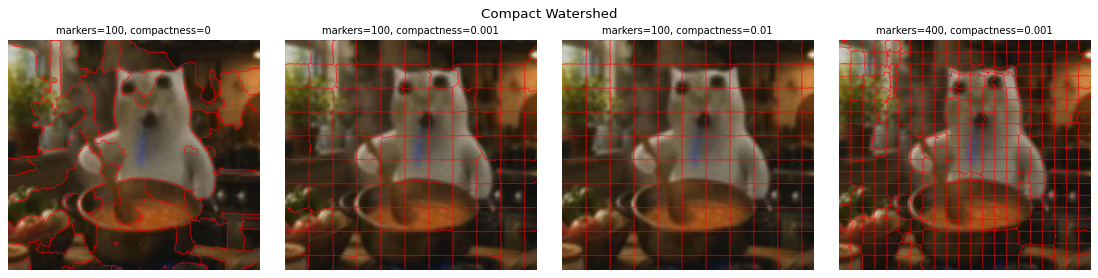

In [27]:
# Variasi compactness (compact watershed) dan marker grid
ims, tts = [], []
for n_mark, comp in [(100, 0), (100, 0.001), (100, 0.01), (400, 0.001)]:
    lbl = sk_watershed(gradient, markers=n_mark, compactness=comp)
    ims.append(mark_boundaries(img_rgb, lbl, color=(1, 0, 0)))
    tts.append(f'markers={n_mark}, compactness={comp}')
show_grid(ims, tts, cols=4, size=3.5, suptitle='Compact Watershed')

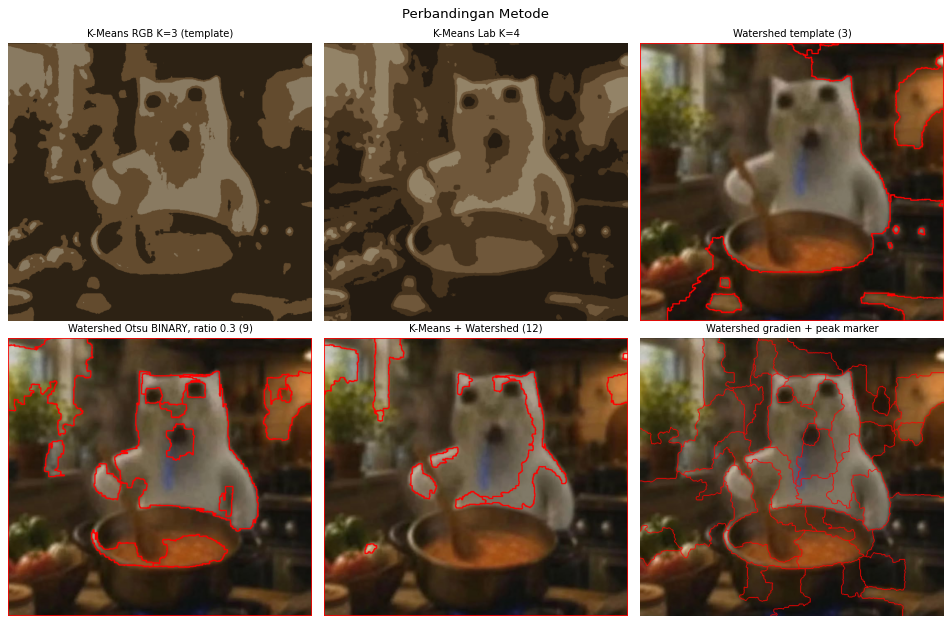

In [28]:
# 14. Ringkasan perbandingan
_, lab4c, cen4c = kmeans_seg(spaces['Lab'].reshape(-1, 3), 4, img.shape)
km4 = np.zeros_like(img_rgb)
for c in range(4):
    km4[lab4c == c] = img_rgb[lab4c == c].mean(axis=0)
r_tpl, _, n_tpl = watershed_pipeline(img, th_inv)
r_best, _, n_best = watershed_pipeline(img, th_bin, dist_ratio=0.3)
fg = (lab4c == np.argmax(cen4c[:, 0])).astype(np.uint8) * 255
r_kw, _, n_kw = watershed_pipeline(img, fg, dist_ratio=0.2)
coords = peak_local_max(ndi.gaussian_filter(gradient.max() - gradient, 3), min_distance=40)
mk = np.zeros(gray.shape, np.int32)
mk[tuple(coords.T)] = np.arange(1, len(coords) + 1)
show_grid([segmented_img, km4, r_tpl, r_best, r_kw, mark_boundaries(img_rgb, sk_watershed(gradient, mk), color=(1, 0, 0))],
          ['K-Means RGB K=3 (template)', 'K-Means Lab K=4', f'Watershed template ({n_tpl})',
           f'Watershed Otsu BINARY, ratio 0.3 ({n_best})', f'K-Means + Watershed ({n_kw})', 'Watershed gradien + peak marker'],
          cols=3, size=4, suptitle='Perbandingan Metode')